In [2]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error       # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split  # 정규화 클래스
from sklearn.preprocessing import StandardScaler

In [3]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [4]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [5]:
train_data = train_data.reshape(-1, 1)
test_data = test_data.reshape(-1, 1)
test_data[:3]

array([[15. ],
       [22.7],
       [21. ]])

In [6]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)

# 데이터 예측
predict = lr.predict(test_data)
print("무게예측 : ",predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

# 기울기,y절편 - LinearRegression() 사용할때 나타남.
print('기울기 : ',lr.coef_)
print('y절편 : ',lr.intercept_)

무게예측 :  [-124.26110198  175.58938733  109.38862995  148.33025194  148.33025194
  148.33025194  121.07111655  693.51295978  265.15511791   70.44700796
  381.97998387 -381.27580711  206.74268492  109.38862995]
train정확도 :  0.9352327087732774
test정확도 :  0.41361436946053587
기울기 :  [38.94162199]
y절편 :  -708.3854318177041


In [15]:
# KNeighborsRegressorv 50 - 1000, 100 - 1000
# 50cm 농어 예측 - 50 - 1132, 100 - 2865
predict2 = lr.predict([[5]])
print("예측무게 : ",predict2)


예측무게 :  [-491.44370461]


In [17]:
in_data = input('농어길이를 입력하세요. 예)52, 5')
in_data = float(in_data)
in_data

52.0

예측무게 :  [-513.67732187]


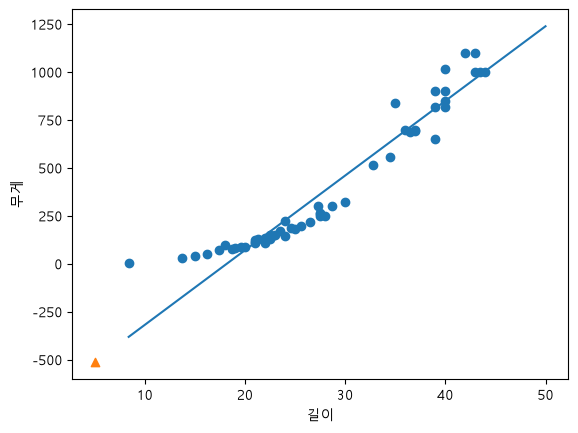

In [8]:
# 길이 입력받아, 무게를 예측하고, 산점도 그래프에 표시하시오.
# 농어길이를 입력하세요. 예)52, 5
in_data = input(' 농어길이를 입력하세요. 예)52, 5')
in_data = float(in_data)
predict = lr.predict([[in_data]])
print('예측무게 : ',predict)

# 산점도 그래프에 표시
# 선 그래프도 함께 표시
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(in_data,predict, marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_])  # 선그래프
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()

예측무게 :  [1298.66527285]


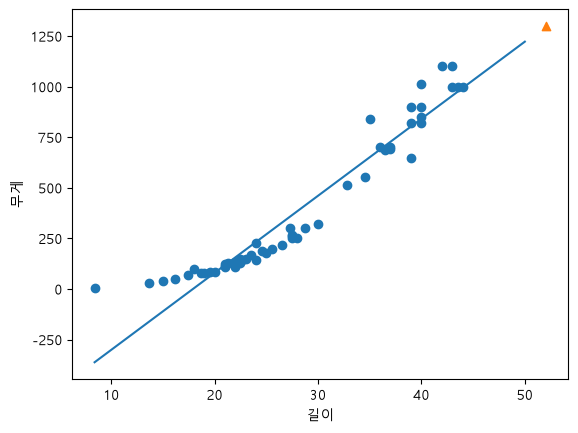

In [14]:
i_data = input('길이를 입력하세요.(예:52)') 
i_data = float(i_data)   # 입력형태 float
predict = lr.predict([[i_data]]) # 2차원배열[[]]
print('예측무게 : ',predict)

# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(i_data,predict,marker='^')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) # 선그래프

plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [11]:
print('기울기 : ',lr.coef_)

기울기 :  [38.08742505]


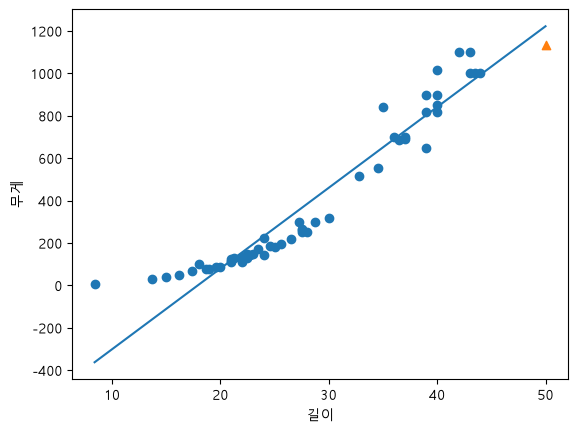

In [13]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(50,1132,marker='^')
# plt.scatter(100,2865,marker='D')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) # 선그래프
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()